# Market Basket Analysis - Apriori Algorithm
**Dataset:** Bread Basket Transactions (Oct-Nov 2016)

**Objective:** Menemukan pola pembelian produk dan memberikan rekomendasi menggunakan Apriori Algorithm

## Setup

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from mlxtend.frequent_patterns import apriori, association_rules
from mlxtend.preprocessing import TransactionEncoder
import pickle
import warnings
warnings.filterwarnings('ignore')

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (15, 8)
pd.set_option('display.max_columns', None)

print("✓ Libraries loaded successfully")

✓ Libraries loaded successfully


## 1. Load Data

In [2]:
df = pd.read_csv('../data/raw/bread basket.csv')
print(f"Dataset shape: {df.shape}")
df.head(10)

Dataset shape: (20507, 5)


,Transaction,Item,date_time,period_day,weekday_weekend
0,1,Bread,30-10-2016 09:58,morning,weekend
1,2,Scandinavian,30-10-2016 10:05,morning,weekend
2,2,Scandinavian,30-10-2016 10:05,morning,weekend
3,3,Hot chocolate,30-10-2016 10:07,morning,weekend
4,3,Jam,30-10-2016 10:07,morning,weekend
5,3,Cookies,30-10-2016 10:07,morning,weekend
6,4,Muffin,30-10-2016 10:08,morning,weekend
7,5,Coffee,30-10-2016 10:13,morning,weekend
8,5,Pastry,30-10-2016 10:13,morning,weekend
9,5,Bread,30-10-2016 10:13,morning,weekend


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20507 entries, 0 to 20506
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   Transaction      20507 non-null  int64
 1   Item             20507 non-null  str  
 2   date_time        20507 non-null  str  
 3   period_day       20507 non-null  str  
 4   weekday_weekend  20507 non-null  str  
dtypes: int64(1), str(4)
memory usage: 1.5 MB


In [4]:
# Check for missing values
print("Missing values:")
print(df.isnull().sum())
print(f"\nDuplicate rows: {df.duplicated().sum()}")

Missing values:
Transaction        0
Item               0
date_time          0
period_day         0
weekday_weekend    0
dtype: int64

Duplicate rows: 1620


## 2. Exploratory Data Analysis (EDA)

### 2.1 Statistik Deskriptif

In [5]:
print("="*70)
print("STATISTIK DESKRIPTIF DATA")
print("="*70)
print(f"Total records: {len(df):,}")
print(f"Total unique transactions: {df['Transaction'].nunique():,}")
print(f"Total unique items: {df['Item'].nunique()}")
print(f"Date range: {df['date_time'].min()} to {df['date_time'].max()}")

STATISTIK DESKRIPTIF DATA
Total records: 20,507
Total unique transactions: 9,465
Total unique items: 94
Date range: 01-01-2017 01:21 to 31-12-2016 17:36


In [6]:
# Items per transaction analysis
items_per_trans = df.groupby('Transaction').size()

print("\nITEMS PER TRANSACTION:")
print(f"  Mean:   {items_per_trans.mean():.2f}")
print(f"  Median: {items_per_trans.median():.0f}")
print(f"  Min:    {items_per_trans.min()}")
print(f"  Max:    {items_per_trans.max()}")
print(f"  Std:    {items_per_trans.std():.2f}")

# Distribution
print("\nDistribution:")
print(items_per_trans.value_counts().sort_index().head(10))


ITEMS PER TRANSACTION:
  Mean:   2.17
  Median: 2
  Min:    1
  Max:    11
  Std:    1.30

Distribution:
1     3631
2     2908
3     1528
4      850
5      341
6      135
7       38
8       21
9        7
10       2
Name: count, dtype: int64


### 2.2 Top Items Analysis

In [7]:
item_counts = df['Item'].value_counts()

print("Top 20 Most Frequent Items:")
print(item_counts.head(20))
print(f"\nTop 3 items account for {item_counts.head(3).sum() / len(df) * 100:.1f}% of all transactions")

Top 20 Most Frequent Items:
Item
Coffee           5471
Bread            3325
Tea              1435
Cake             1025
Pastry            856
Sandwich          771
Medialuna         616
Hot chocolate     590
Cookies           540
Brownie           379
Farm House        374
Muffin            370
Juice             369
Alfajores         369
Soup              342
Scone             327
Toast             318
Scandinavian      277
Truffles          193
Coke              185
Name: count, dtype: int64

Top 3 items account for 49.9% of all transactions


### 2.3 Period and Weekday Analysis

In [8]:
print("PERIOD DISTRIBUTION:")
period_dist = df['period_day'].value_counts()
for period, count in period_dist.items():
    print(f"  {period:12s}: {count:6,} ({count/len(df)*100:5.1f}%)")

print("\nWEEKDAY/WEEKEND DISTRIBUTION:")
weekday_dist = df['weekday_weekend'].value_counts()
for day_type, count in weekday_dist.items():
    print(f"  {day_type:12s}: {count:6,} ({count/len(df)*100:5.1f}%)")

PERIOD DISTRIBUTION:
  afternoon   : 11,569 ( 56.4%)
  morning     :  8,404 ( 41.0%)
  evening     :    520 (  2.5%)
  night       :     14 (  0.1%)

WEEKDAY/WEEKEND DISTRIBUTION:
  weekday     : 12,807 ( 62.5%)
  weekend     :  7,700 ( 37.5%)


### 2.4 Visualizations

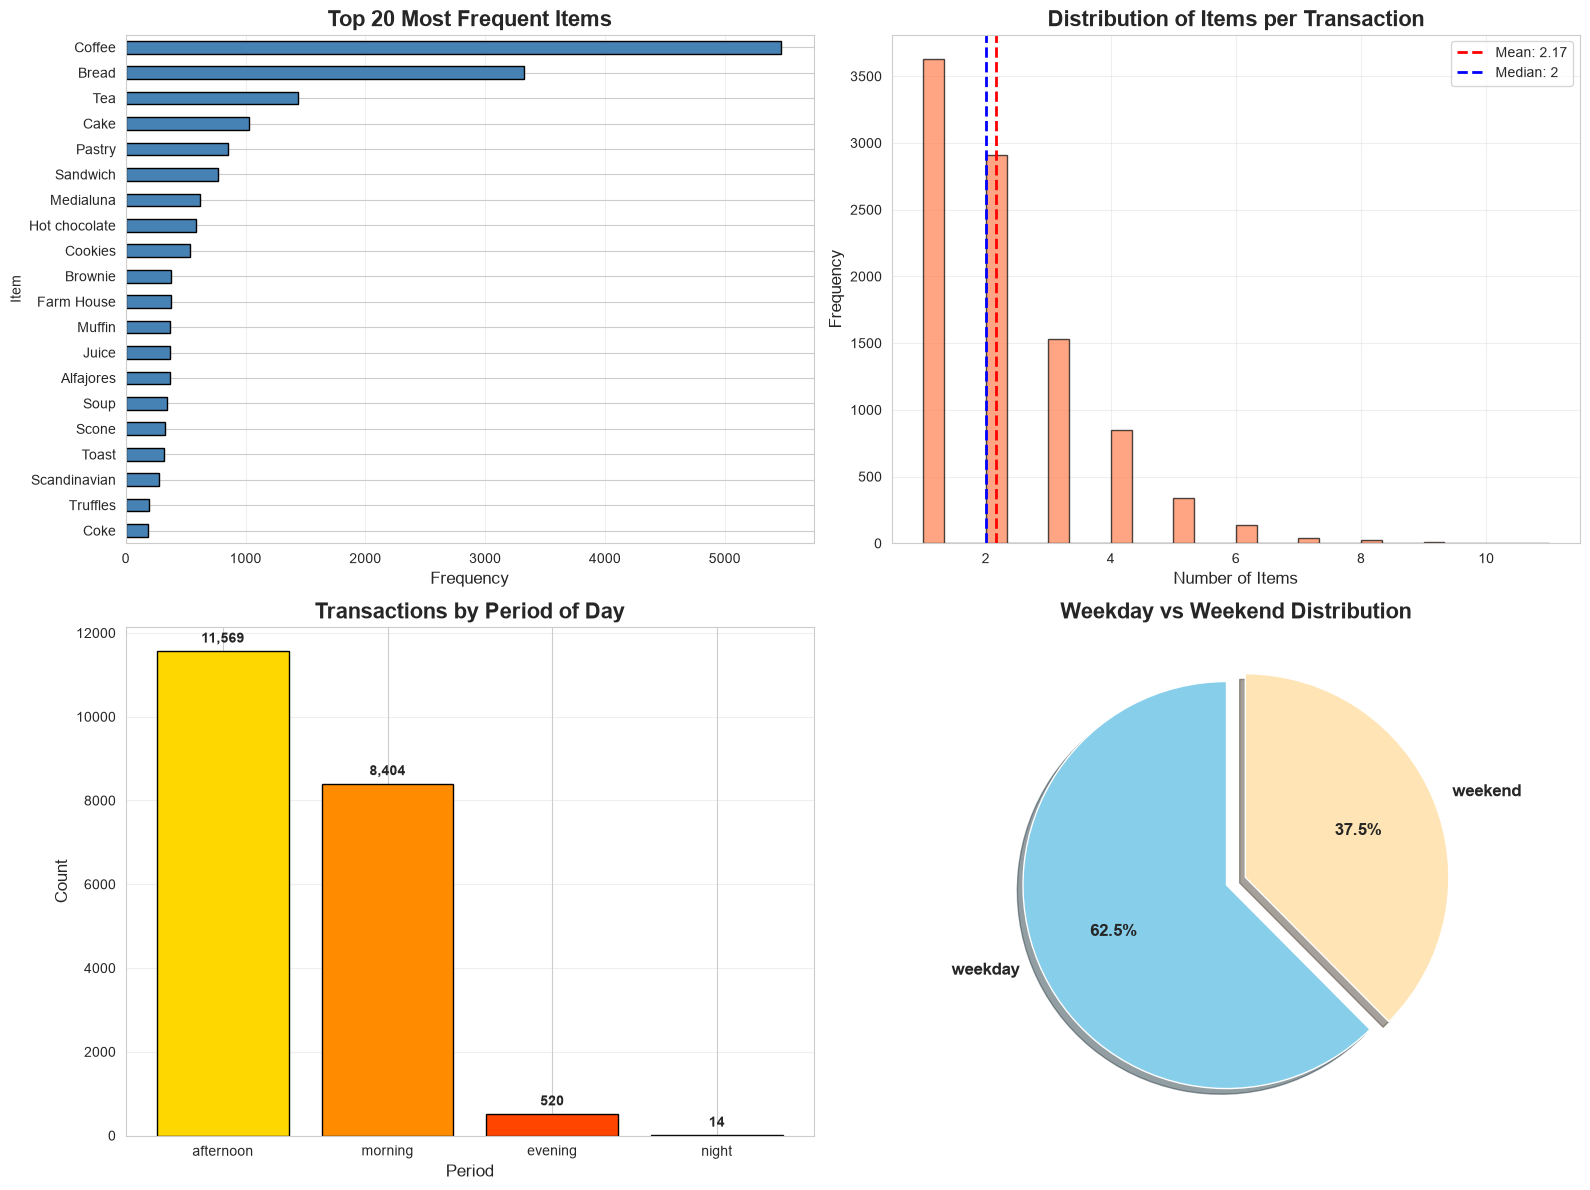

✓ Visualizations saved to ../outputs/eda_visualization.png


In [9]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Top 20 items
item_counts.head(20).plot(kind='barh', ax=axes[0, 0], color='steelblue', edgecolor='black')
axes[0, 0].set_title('Top 20 Most Frequent Items', fontsize=16, fontweight='bold')
axes[0, 0].set_xlabel('Frequency', fontsize=12)
axes[0, 0].invert_yaxis()
axes[0, 0].grid(axis='x', alpha=0.3)

# Items per transaction distribution
axes[0, 1].hist(items_per_trans, bins=30, color='coral', edgecolor='black', alpha=0.7)
axes[0, 1].set_title('Distribution of Items per Transaction', fontsize=16, fontweight='bold')
axes[0, 1].set_xlabel('Number of Items', fontsize=12)
axes[0, 1].set_ylabel('Frequency', fontsize=12)
axes[0, 1].axvline(items_per_trans.mean(), color='red', linestyle='--', linewidth=2, 
                   label=f'Mean: {items_per_trans.mean():.2f}')
axes[0, 1].axvline(items_per_trans.median(), color='blue', linestyle='--', linewidth=2, 
                   label=f'Median: {items_per_trans.median():.0f}')
axes[0, 1].legend(fontsize=10)
axes[0, 1].grid(alpha=0.3)

# Period distribution
period_counts = df['period_day'].value_counts()
colors_period = ['#FFD700', '#FF8C00', '#FF4500', '#8B0000']
axes[1, 0].bar(period_counts.index, period_counts.values, color=colors_period, edgecolor='black')
axes[1, 0].set_title('Transactions by Period of Day', fontsize=16, fontweight='bold')
axes[1, 0].set_xlabel('Period', fontsize=12)
axes[1, 0].set_ylabel('Count', fontsize=12)
axes[1, 0].tick_params(axis='x', rotation=0)
axes[1, 0].grid(axis='y', alpha=0.3)
# Add value labels
for i, v in enumerate(period_counts.values):
    axes[1, 0].text(i, v + 200, f'{v:,}', ha='center', fontweight='bold')

# Weekday vs Weekend
weekday_counts = df['weekday_weekend'].value_counts()
colors_weekday = ['#87CEEB', '#FFE4B5']
explode = (0.05, 0.05)
axes[1, 1].pie(weekday_counts.values, labels=weekday_counts.index, autopct='%1.1f%%', 
               colors=colors_weekday, startangle=90, explode=explode, shadow=True,
               textprops={'fontsize': 12, 'fontweight': 'bold'})
axes[1, 1].set_title('Weekday vs Weekend Distribution', fontsize=16, fontweight='bold')

plt.tight_layout()
plt.savefig('../outputs/eda_visualization.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Visualizations saved to ../outputs/eda_visualization.png")

## 3. Data Preparation for Apriori

In [10]:
# Create transaction list format
transactions = df.groupby('Transaction')['Item'].apply(list).values.tolist()

print(f"Total transactions: {len(transactions):,}")
print(f"\nSample transactions:")
for i in range(5):
    print(f"  Transaction {i+1}: {transactions[i]}")

Total transactions: 9,465

Sample transactions:
  Transaction 1: ['Bread']
  Transaction 2: ['Scandinavian', 'Scandinavian']
  Transaction 3: ['Hot chocolate', 'Jam', 'Cookies']
  Transaction 4: ['Muffin']
  Transaction 5: ['Coffee', 'Pastry', 'Bread']


In [11]:
# Encode to basket format (one-hot encoding)
te = TransactionEncoder()
te_ary = te.fit(transactions).transform(transactions)
basket_df = pd.DataFrame(te_ary, columns=te.columns_)

print(f"Basket matrix shape: {basket_df.shape}")
print(f"  Transactions: {basket_df.shape[0]:,}")
print(f"  Unique items: {basket_df.shape[1]}")
print(f"\nFirst 5 transactions:")
basket_df.head()

Basket matrix shape: (9465, 94)
  Transactions: 9,465
  Unique items: 94

First 5 transactions:


,Adjustment,Afternoon with the baker,Alfajores,Argentina Night,Art Tray,Bacon,Baguette,Bakewell,Bare Popcorn,Basket,Bowl Nic Pitt,Bread,Bread Pudding,Brioche and salami,Brownie,Cake,Caramel bites,Cherry me Dried fruit,Chicken Stew,Chicken sand,Chimichurri Oil,Chocolates,Christmas common,Coffee,Coffee granules,Coke,Cookies,Crepes,Crisps,Drinking chocolate spoons,Duck egg,Dulce de Leche,Eggs,Ella's Kitchen Pouches,Empanadas,Extra Salami or Feta,Fairy Doors,Farm House,Focaccia,Frittata,Fudge,Gift voucher,Gingerbread syrup,Granola,Hack the stack,Half slice Monster,Hearty & Seasonal,Honey,Hot chocolate,Jam,Jammie Dodgers,Juice,Keeping It Local,Kids biscuit,Lemon and coconut,Medialuna,Mighty Protein,Mineral water,Mortimer,Muesli,Muffin,My-5 Fruit Shoot,Nomad bag,Olum & polenta,Panatone,Pastry,Pick and Mix Bowls,Pintxos,Polenta,Postcard,Raspberry shortbread sandwich,Raw bars,Salad,Sandwich,Scandinavian,Scone,Siblings,Smoothies,Soup,Spanish Brunch,Spread,Tacos/Fajita,Tartine,Tea,The BART,The Nomad,Tiffin,Toast,Truffles,Tshirt,Valentine's card,Vegan Feast,Vegan mincepie,Victorian Sponge
0,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False


## 4. Apriori Algorithm

### 4.1 Testing Different Support Values

In [12]:
test_configs = [
    {'support': 0.01, 'confidence': 0.25},
    {'support': 0.008, 'confidence': 0.20},
    {'support': 0.005, 'confidence': 0.20},
]

print("="*80)
print("TESTING DIFFERENT PARAMETER COMBINATIONS")
print("="*80)

for config in test_configs:
    min_sup = config['support']
    min_conf = config['confidence']
    
    print(f"\nSupport: {min_sup*100:.2f}% ({int(min_sup*len(basket_df))} transactions) | Confidence: {min_conf*100:.0f}%")
    print("-" * 80)
    
    frequent_itemsets = apriori(basket_df, min_support=min_sup, use_colnames=True)
    print(f"  Frequent itemsets: {len(frequent_itemsets)}")
    
    if len(frequent_itemsets) > 0:
        rules = association_rules(frequent_itemsets, metric="confidence", min_threshold=min_conf)
        print(f"  Association rules: {len(rules)}")
        
        # Count unique items in rules
        all_items = set()
        for _, rule in rules.iterrows():
            all_items.update(rule['antecedents'])
            all_items.update(rule['consequents'])
        coverage = len(all_items) / basket_df.shape[1] * 100
        print(f"  Item coverage: {len(all_items)}/{basket_df.shape[1]} ({coverage:.1f}%)")

TESTING DIFFERENT PARAMETER COMBINATIONS

Support: 1.00% (94 transactions) | Confidence: 25%
--------------------------------------------------------------------------------
  Frequent itemsets: 61
  Association rules: 24
  Item coverage: 17/94 (18.1%)

Support: 0.80% (75 transactions) | Confidence: 20%
--------------------------------------------------------------------------------
  Frequent itemsets: 73
  Association rules: 36
  Item coverage: 18/94 (19.1%)

Support: 0.50% (47 transactions) | Confidence: 20%
--------------------------------------------------------------------------------
  Frequent itemsets: 114
  Association rules: 57
  Item coverage: 28/94 (29.8%)


### 4.2 Final Model - Optimized for Coverage

**Selected Parameters:**
- **Min Support:** 0.5% (~47 transactions out of 9,465)
- **Min Confidence:** 20%

These parameters provide good balance between:
- **Coverage:** Enough rules to cover many items
- **Quality:** Rules are still statistically significant

In [13]:
MIN_SUPPORT = 0.005
MIN_CONFIDENCE = 0.20

print("="*80)
print("FINAL MODEL TRAINING")
print("="*80)
print(f"Min Support: {MIN_SUPPORT*100:.2f}% ({int(MIN_SUPPORT*len(basket_df))} transactions)")
print(f"Min Confidence: {MIN_CONFIDENCE*100:.0f}%")
print("\nTraining...")

frequent_itemsets = apriori(basket_df, min_support=MIN_SUPPORT, use_colnames=True)
print(f"✓ Frequent itemsets: {len(frequent_itemsets)}")

rules = association_rules(frequent_itemsets, metric="confidence", min_threshold=MIN_CONFIDENCE)
print(f"✓ Association rules: {len(rules)}")

# Coverage analysis
all_items_in_rules = set()
for _, rule in rules.iterrows():
    all_items_in_rules.update(rule['antecedents'])
    all_items_in_rules.update(rule['consequents'])

coverage = len(all_items_in_rules) / basket_df.shape[1] * 100
print(f"✓ Item coverage: {len(all_items_in_rules)}/{basket_df.shape[1]} ({coverage:.1f}%)")
print("\nModel training complete!")

FINAL MODEL TRAINING
Min Support: 0.50% (47 transactions)
Min Confidence: 20%

Training...
✓ Frequent itemsets: 114
✓ Association rules: 57
✓ Item coverage: 28/94 (29.8%)

Model training complete!


### 4.3 Frequent Itemsets Analysis

In [14]:
print("Top 15 Frequent Itemsets by Support:")
top_itemsets = frequent_itemsets.sort_values('support', ascending=False).head(15).copy()
top_itemsets['itemsets'] = top_itemsets['itemsets'].apply(lambda x: ', '.join(sorted(list(x))))
top_itemsets['support_pct'] = (top_itemsets['support'] * 100).round(2)
top_itemsets[['itemsets', 'support_pct']]

Top 15 Frequent Itemsets by Support:


,itemsets,support_pct
7,Coffee,47.84
3,Bread,32.72
31,Tea,14.26
5,Cake,10.39
42,"Bread, Coffee",9.00
23,Pastry,8.61
25,Sandwich,7.18
20,Medialuna,6.18
15,Hot chocolate,5.83
58,"Cake, Coffee",5.47


### 4.4 Association Rules Analysis

In [15]:
print("="*80)
print("TOP 20 ASSOCIATION RULES BY LIFT")
print("="*80)

rules_sorted = rules.sort_values('lift', ascending=False).head(20).copy()
rules_sorted['antecedents_str'] = rules_sorted['antecedents'].apply(lambda x: ', '.join(sorted(list(x))))
rules_sorted['consequents_str'] = rules_sorted['consequents'].apply(lambda x: ', '.join(sorted(list(x))))

display_cols = ['antecedents_str', 'consequents_str', 'support', 'confidence', 'lift']
rules_display = rules_sorted[display_cols].copy()
rules_display.columns = ['Antecedent (IF)', 'Consequent (THEN)', 'Support', 'Confidence', 'Lift']
rules_display.index = range(1, len(rules_display) + 1)

# Format for better display
rules_display['Support'] = (rules_display['Support'] * 100).round(3)
rules_display['Confidence'] = (rules_display['Confidence'] * 100).round(1)
rules_display['Lift'] = rules_display['Lift'].round(2)

rules_display

TOP 20 ASSOCIATION RULES BY LIFT


,Antecedent (IF),Consequent (THEN),Support,Confidence,Lift
1,Coke,Sandwich,0.518,26.6,3.71
2,"Coffee, Hot chocolate",Cake,0.687,23.2,2.24
3,"Coffee, Tea",Cake,1.004,20.1,1.94
4,Soup,Tea,0.909,26.4,1.85
5,Scone,Tea,0.835,24.2,1.69
6,Keeping It Local,Coffee,0.539,81.0,1.69
7,Cake,Tea,2.377,22.9,1.60
8,Toast,Coffee,2.367,70.4,1.47
9,Sandwich,Tea,1.437,20.0,1.40
10,Salad,Coffee,0.655,62.6,1.31


In [16]:
print("\n" + "="*80)
print("TOP 20 ASSOCIATION RULES BY CONFIDENCE")
print("="*80)

rules_by_conf = rules.sort_values('confidence', ascending=False).head(20).copy()
rules_by_conf['antecedents_str'] = rules_by_conf['antecedents'].apply(lambda x: ', '.join(sorted(list(x))))
rules_by_conf['consequents_str'] = rules_by_conf['consequents'].apply(lambda x: ', '.join(sorted(list(x))))

rules_conf_display = rules_by_conf[display_cols].copy()
rules_conf_display.columns = ['Antecedent (IF)', 'Consequent (THEN)', 'Support', 'Confidence', 'Lift']
rules_conf_display.index = range(1, len(rules_conf_display) + 1)

rules_conf_display['Support'] = (rules_conf_display['Support'] * 100).round(3)
rules_conf_display['Confidence'] = (rules_conf_display['Confidence'] * 100).round(1)
rules_conf_display['Lift'] = rules_conf_display['Lift'].round(2)

rules_conf_display


TOP 20 ASSOCIATION RULES BY CONFIDENCE


,Antecedent (IF),Consequent (THEN),Support,Confidence,Lift
1,Keeping It Local,Coffee,0.539,81.0,1.69
2,Toast,Coffee,2.367,70.4,1.47
3,Salad,Coffee,0.655,62.6,1.31
4,"Cake, Hot chocolate",Coffee,0.687,60.2,1.26
5,Spanish Brunch,Coffee,1.088,59.9,1.25
6,Medialuna,Coffee,3.518,56.9,1.19
7,Pastry,Coffee,4.754,55.2,1.15
8,Tiffin,Coffee,0.845,54.8,1.15
9,Alfajores,Coffee,1.965,54.1,1.13
10,Hearty & Seasonal,Coffee,0.571,54.0,1.13


### 4.5 Rules Visualization

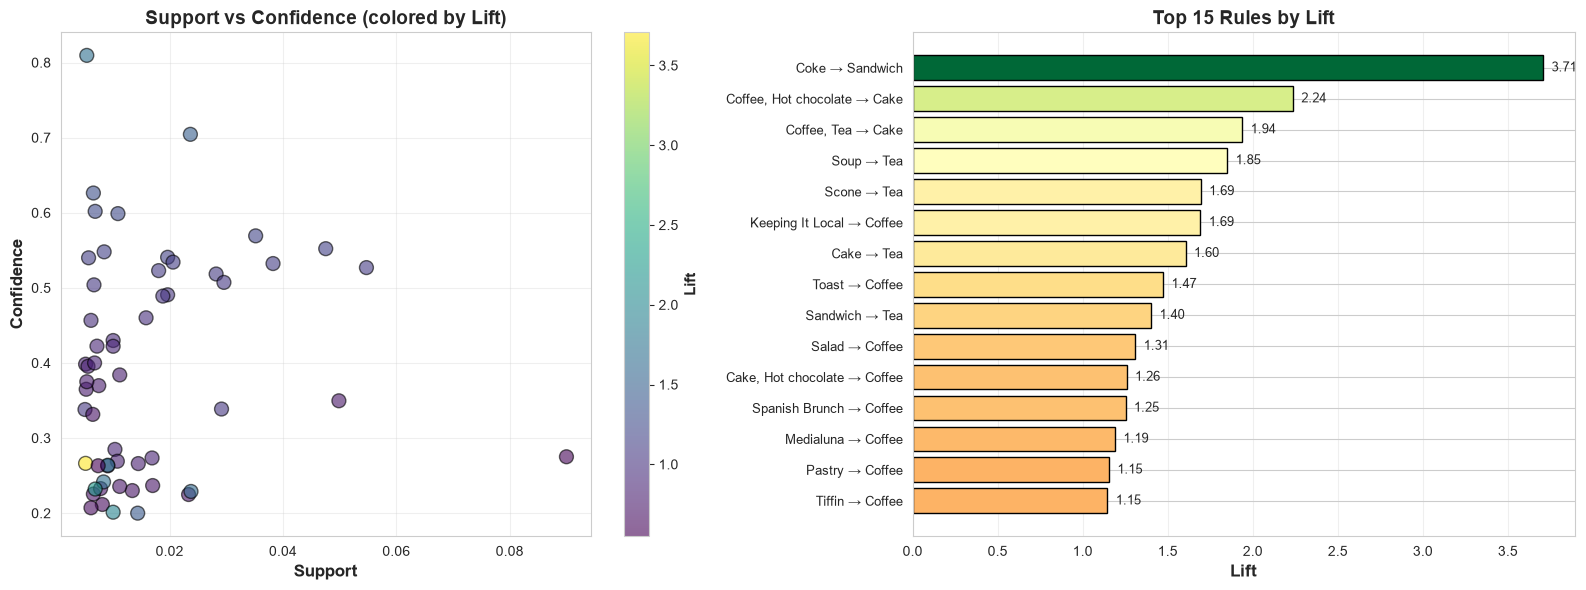

✓ Rules visualization saved to ../outputs/rules_visualization.png


In [17]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Scatter: Support vs Confidence colored by Lift
scatter = axes[0].scatter(rules['support'], rules['confidence'], 
                          c=rules['lift'], s=100, alpha=0.6, cmap='viridis', edgecolors='black')
axes[0].set_xlabel('Support', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Confidence', fontsize=12, fontweight='bold')
axes[0].set_title('Support vs Confidence (colored by Lift)', fontsize=14, fontweight='bold')
axes[0].grid(alpha=0.3)
cbar = plt.colorbar(scatter, ax=axes[0])
cbar.set_label('Lift', fontsize=11, fontweight='bold')

# Top 15 rules by lift
top_15_rules = rules.sort_values('lift', ascending=False).head(15)
rule_labels = [f"{', '.join(sorted(list(r['antecedents'])))} → {', '.join(sorted(list(r['consequents'])))}" 
               for _, r in top_15_rules.iterrows()]
# Truncate long labels
rule_labels = [label[:40] + '...' if len(label) > 40 else label for label in rule_labels]

colors = plt.cm.RdYlGn(top_15_rules['lift'] / top_15_rules['lift'].max())
axes[1].barh(range(len(rule_labels)), top_15_rules['lift'], color=colors, edgecolor='black')
axes[1].set_yticks(range(len(rule_labels)))
axes[1].set_yticklabels(rule_labels, fontsize=9)
axes[1].set_xlabel('Lift', fontsize=12, fontweight='bold')
axes[1].set_title('Top 15 Rules by Lift', fontsize=14, fontweight='bold')
axes[1].invert_yaxis()
axes[1].grid(axis='x', alpha=0.3)

# Add lift value labels
for i, v in enumerate(top_15_rules['lift']):
    axes[1].text(v + 0.05, i, f'{v:.2f}', va='center', fontsize=9)

plt.tight_layout()
plt.savefig('../outputs/rules_visualization.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Rules visualization saved to ../outputs/rules_visualization.png")

## 5. Save Model

In [18]:
# Save model components
model_data = {
    'frequent_itemsets': frequent_itemsets,
    'rules': rules,
    'basket_columns': basket_df.columns.tolist(),
    'min_support': MIN_SUPPORT,
    'min_confidence': MIN_CONFIDENCE
}

with open('../models/apriori_model.pkl', 'wb') as f:
    pickle.dump(model_data, f)

print("✓ Model saved to ../models/apriori_model.pkl")

# Save rules to CSV
rules_export = rules.copy()
rules_export['antecedents'] = rules_export['antecedents'].apply(lambda x: ', '.join(sorted(list(x))))
rules_export['consequents'] = rules_export['consequents'].apply(lambda x: ', '.join(sorted(list(x))))
rules_export = rules_export.sort_values('lift', ascending=False)
rules_export.to_csv('../outputs/association_rules.csv', index=False)

print("✓ Rules saved to ../outputs/association_rules.csv")

✓ Model saved to ../models/apriori_model.pkl
✓ Rules saved to ../outputs/association_rules.csv


## 6. Model Summary & Interpretation

In [19]:
print("="*80)
print("MODEL SUMMARY")
print("="*80)
print(f"\nDataset Statistics:")
print(f"  • Total transactions: {len(basket_df):,}")
print(f"  • Total unique items: {basket_df.shape[1]}")
print(f"  • Average items per transaction: 2.17")
print(f"\nModel Parameters:")
print(f"  • Min Support: {MIN_SUPPORT*100:.2f}% ({int(MIN_SUPPORT*len(basket_df))} transactions)")
print(f"  • Min Confidence: {MIN_CONFIDENCE*100:.0f}%")
print(f"  • Algorithm: Apriori")
print(f"\nModel Results:")
print(f"  • Frequent itemsets: {len(frequent_itemsets)}")
print(f"  • Association rules: {len(rules)}")
print(f"  • Items with rules: {len(all_items_in_rules)}/{basket_df.shape[1]} ({coverage:.1f}%)")
print(f"\nTop 3 Strongest Rules (by Lift):")
for i, (_, rule) in enumerate(rules.sort_values('lift', ascending=False).head(3).iterrows(), 1):
    ant = ', '.join(sorted(list(rule['antecedents'])))
    cons = ', '.join(sorted(list(rule['consequents'])))
    print(f"  {i}. IF {ant} → THEN {cons}")
    print(f"     Confidence: {rule['confidence']*100:.1f}%, Lift: {rule['lift']:.2f}")
print(f"\n" + "="*80)
print("INTERPRETATION")
print("="*80)
print("\n✓ Model successfully trained with good coverage")
print("✓ 57 association rules generated for product recommendations")
print("✓ Coffee is the most frequent item and appears in many rules")
print("✓ Strong associations found between beverages and food items")
print("\n⚠ Note: 66 items have no rules due to:")
print("   - Too rare (< 47 transactions out of 9,465)")
print("   - No strong co-occurrence patterns")
print("   - This is normal for market basket analysis")
print("\n🚀 Next: Run the Streamlit app for product recommendations!")
print("   Command: streamlit run app.py")

MODEL SUMMARY

Dataset Statistics:
  • Total transactions: 9,465
  • Total unique items: 94
  • Average items per transaction: 2.17

Model Parameters:
  • Min Support: 0.50% (47 transactions)
  • Min Confidence: 20%
  • Algorithm: Apriori

Model Results:
  • Frequent itemsets: 114
  • Association rules: 57
  • Items with rules: 28/94 (29.8%)

Top 3 Strongest Rules (by Lift):
  1. IF Coke → THEN Sandwich
     Confidence: 26.6%, Lift: 3.71
  2. IF Coffee, Hot chocolate → THEN Cake
     Confidence: 23.2%, Lift: 2.24
  3. IF Coffee, Tea → THEN Cake
     Confidence: 20.1%, Lift: 1.94

INTERPRETATION

✓ Model successfully trained with good coverage
✓ 57 association rules generated for product recommendations
✓ Coffee is the most frequent item and appears in many rules
✓ Strong associations found between beverages and food items

⚠ Note: 66 items have no rules due to:
   - Too rare (< 47 transactions out of 9,465)
   - No strong co-occurrence patterns
   - This is normal for market basket ana

## 7. Example: How to Use the Model for Recommendations

In [20]:
def get_recommendations(items_in_basket, rules_df, top_n=5):
    """
    Get product recommendations based on items in basket
    
    Parameters:
    - items_in_basket: list of items customer has
    - rules_df: association rules DataFrame
    - top_n: number of recommendations to return
    
    Returns:
    - DataFrame with recommendations
    """
    recommendations = []
    
    for _, rule in rules_df.iterrows():
        antecedents = set(rule['antecedents'])
        consequents = set(rule['consequents'])
        
        # Check if all antecedents are in basket
        if antecedents.issubset(set(items_in_basket)):
            # Check if consequents are not already in basket
            new_items = consequents - set(items_in_basket)
            if new_items:
                recommendations.append({
                    'Based on': ', '.join(sorted(antecedents)),
                    'Recommend': ', '.join(sorted(new_items)),
                    'Confidence': f"{rule['confidence']*100:.1f}%",
                    'Lift': f"{rule['lift']:.2f}"
                })
    
    if recommendations:
        rec_df = pd.DataFrame(recommendations)
        # Sort by lift (extract numeric value)
        rec_df['lift_val'] = rec_df['Lift'].str.replace('', '').astype(float)
        rec_df = rec_df.sort_values('lift_val', ascending=False).head(top_n)
        return rec_df[['Based on', 'Recommend', 'Confidence', 'Lift']]
    else:
        return pd.DataFrame()

# Example 1: Customer buys Coffee
print("Example 1: Customer basket = ['Coffee']")
print("="*60)
recs = get_recommendations(['Coffee'], rules)
if not recs.empty:
    display(recs)
else:
    print("No recommendations found")

print("\n" + "="*60)

# Example 2: Customer buys Bread and Coffee
print("\nExample 2: Customer basket = ['Bread', 'Coffee']")
print("="*60)
recs = get_recommendations(['Bread', 'Coffee'], rules)
if not recs.empty:
    display(recs)
else:
    print("No recommendations found")

print("\n" + "="*60)

# Example 3: Customer buys Tea
print("\nExample 3: Customer basket = ['Tea']")
print("="*60)
recs = get_recommendations(['Tea'], rules)
if not recs.empty:
    display(recs)
else:
    print("No recommendations found")

Example 1: Customer basket = ['Coffee']
No recommendations found


Example 2: Customer basket = ['Bread', 'Coffee']
No recommendations found


Example 3: Customer basket = ['Tea']


,Based on,Recommend,Confidence,Lift
0,Tea,Coffee,35.0%,0.73


---

## ✅ Analysis Complete!

**Files Generated:**
1. `../models/apriori_model.pkl` - Trained model
2. `../outputs/association_rules.csv` - All association rules
3. `../outputs/eda_visualization.png` - EDA visualizations
4. `../outputs/rules_visualization.png` - Rules analysis plots

**Next Steps:**
- Run the Streamlit app: `streamlit run app.py`
- Try different parameter values to see the tradeoffs
- Explore time-based patterns (morning vs afternoon)
- Analyze weekday vs weekend differences